<H1>TwoSlit</H1> 
Geophone analysis, simulation and plan. 
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 16-Feb-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
 https://en.wikipedia.org/wiki/Geographic_coordinate_conversion#From_geodetic_to_ECEF_coordinates 
 <br>
https://pyproj4.github.io/pyproj/stable/
<br>
https://pyproj4.github.io/pyproj/stable/examples.html
<br>
https://proj.org/faq.html#what-is-the-best-format-for-describing-coordinate-reference-systems
<hr>
<H2> Notes </H2>
<br> 
There is one hole that is identified with a shallow and deep geophone pair. 

There is a hole that I don't know what is going on with it, I need to use a tire iron to open it. 

The other holes are all void. 
<hr>
<H2> Things to do </H2>
<ol>
    <li> Use a survey grade antenna and GPS to determine hole locations </li>
    <li> Use tape measure to measure the distance on the surface between the holes. Can do real survey</li>
    <li> Need to make a mould or find the connector. Think it is a KCK\ </li>
    <li> What is a decent exciter - I'm guessing impulse. </li>
    <li> characterize at the surface </li>
    <li> Probably doesn't hurt to understand the variation in altitude of the surface - contour plot. </li>
</ol>
<hr>
<ol>
    <li> From all available points, measure the response to each geophone from a surface mounted exciter. These should be time synched to the best of our ability. </li>
    <li> measure the same but at the water table in each bore hole, measure the depth of the water table relative to the mean geoid or some other reference.</li>
    <li> Measure from the midpoint between the surface and the water table. </li>
</ol>

We will have to deal with coupling between the exciter and the soil/water. 

The water table should be at a constant altitude and serves as a Z reference. It will also have hard reflections when the excitation is coming from something not in the water. 

Do multiple runs between each point and then do a miminimiation between the $\delta t$

Can we extrapolate the speed of sound in the local medium?

In [2]:
# my standard includes
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.constants as const
# projection library Lat-Lon to XY
from pyproj import Proj
from pyproj import Geod

In [3]:
# The points to date. 
class GeoPoint:
    def __init__(self):
        """
        Make all values public so we can use it like a struct. 
        """
        self.name = ""
        self.Lat = 41.5
        self.Lon = 71.3
        self.Z   = 30.0
        self.X   = 0
        self.Y   = 0
        
    def __str__(self):
        return f'{self.name} {self.Lat:.6f} {self.Lon:.6f} {self.Z:.2f} {self.X:.6f} {self.Y:.6f}' 
        

In [4]:
# initialize the projection library
# Calculate UTM zone, lat lon here is rough
Latitude  = 41.5
Longitude = -71.316
Zone = Longitude + 180.0 # in degrees
Zone = np.ceil(Zone/6.0)
print ("Zone=",Zone)
#
# https://coordinates-converter.com/en/decimal/41.499976,-71.315992?karte=OpenStreetMap&zoom=8
#
# Lat = 41.5, Lon = -71.316
#
# Zone: 19
# False Easting: 306694.305
# False Northing: 4596851.081
#p = Proj(proj='utm',zone=Zone,ellps='WGS84') # use kwargs
p = Proj(proj='utm',ellps='WGS84', zone=19)
x,y = p(Longitude, Latitude)
'x=%9.3f y=%11.3f' % (x,y)
#
# example or range and bearing
#
# specify the lat/lons of some cities.
newport_lat=41.5; newport_lon=-71.316
boston_lat = 42.+(15./60.); boston_lon = -71.-(7./60.)
portland_lat = 45.+(31./60.); portland_lon = -123.-(41./60.)
newyork_lat = 40.+(47./60.); newyork_lon = -73.-(58./60.)
london_lat = 51.+(32./60.); london_lon = -(5./60.)
#
# https://pyproj4.github.io/pyproj/stable/api/geod.html
#g = Geod(ellps='clrk66')
g = Geod(ellps='WGS84')
# compute forward and back azimuths, plus distance
# between Boston and Portland.
az12,az21,dist = g.inv(boston_lon,boston_lat,portland_lon,portland_lat)
f"{az12:.3f} {az21:.3f} {dist:.3f}"
#
#'-66.531 75.654 4164192.708'
#

Zone= 19.0


'-66.530 75.654 4164074.239'

In [5]:
# Make a list of known points, these are pretty sketchy
Point1 = GeoPoint()
Point1.name = "A"
 
Point2 = GeoPoint()
Point2.name = "B"
Point2.Lat  = 41.53519
Point2.Lon  = -71.24229
Point2.Z    = 33.0

Point3 = GeoPoint()
Point3.name = "C"
Point3.Lat = 41.535165
Point3.Lon = -71.242389
Point3.Z   = 34


In [6]:
#Cycle through th points and assign XY
Point1.X,Point1.Y = p(Point1.Lon, Point1.Lat)
Point2.X,Point2.Y = p(Point2.Lon, Point2.Lat)
Point3.X,Point3.Y = p(Point2.Lon, Point2.Lat)
print(Point2)

B 41.535190 -71.242290 33.00 312947.758492 4600598.649953


In [7]:
# finaly range bearing
az12,az21,dist = g.inv(Point2.Lon,Point2.Lat,Point3.Lon,Point3.Lat)
f"{az12:.3f} {az21:.3f} {dist:.3f}"


'-108.577 71.423 8.716'

<H1> References for calibration in Situ</H1>
https://www.usgs.gov/publications/improved-phase-ellipse-method-situ-geophone-calibration <br>


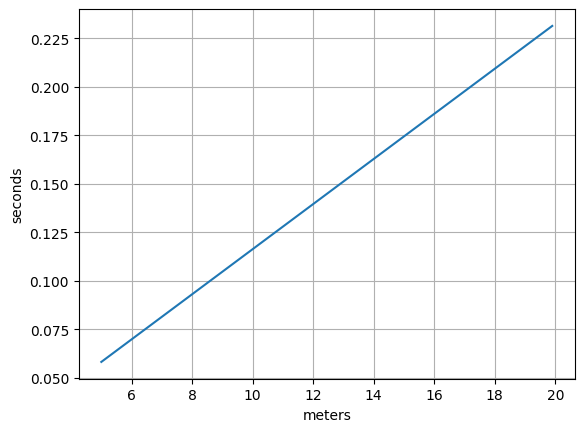

In [10]:
# Now look at the various propigation speeds
# Determine the jitter in the signal permitted and the decimation of signal 
# ADC
C_Soil = 86    # m/s but can be as high as 300m/s
C_Water = 1500 # m/s but also highly variable. 
# 
x = np.arange(5,20,0.1)  # Meters
y = x/C_Soil
plt.plot(x,y)
plt.xlabel('meters')
plt.ylabel('seconds')
plt.grid()

In [15]:
# assume maximum decimation in spatial coordinates is 
dr = 0.01       # meters
dt = dr/C_Soil
SampleRate = 2048
print('dt: ' , dt, ' dts: ', 1.0/SampleRate, ' ', dt*SampleRate)

dt:  0.00011627906976744187  dts:  0.00048828125   0.23813953488372094


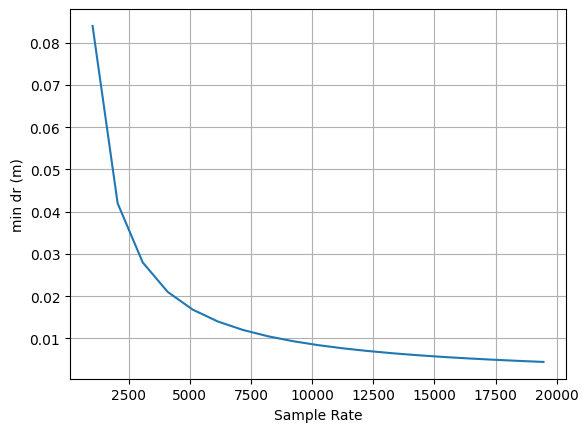

In [17]:
x = np.arange(1024.0, 20*1024, 1024)
y = C_Soil/x
plt.plot(x,y)
plt.xlabel('Sample Rate')
plt.ylabel('min dr (m)')
plt.grid()

Once we get a system setup for testing, want to run many samples for pulses. <br>
Soil Attenuation 8dB/ft at 1kHz<br>
35dB/ft at 8kHz